# 基于 sklearn 三种回归算法的红葡萄酒质量数据集训练与预测 —— 实验报告

## 作业要求

> 请使用 sklearn 库的回归算法对葡萄酒质量数据集进行训练及预测。

仿照 0909 实验中鸢尾花/糖尿病数据集 “加载数据 → 选择模型 → 训练 → 预测 → 评分” 的流程，本报告对 **UCI 红葡萄酒质量数据集**（`report_assets/winequality-red.csv`，1599 条样本、11 个理化特征、`quality` 为质量评分）分别使用 **多元线性回归**、**岭回归（Ridge）**、**Lasso 回归** 三种 sklearn 回归算法进行训练与预测，并对结果进行评估与对比。

## 一、实验目的

1. 复用 0909 的 sklearn 回归建模流程，对自定义 CSV 数据集（非内置数据集）完成训练与预测；
2. 掌握线性回归、Ridge（L2 正则化）、Lasso（L1 正则化）三种回归算法的实现与对比；
3. 学会使用 `RidgeCV` / `LassoCV` 通过交叉验证选择正则化强度 `alpha`；
4. 掌握回归任务的评估指标：MSE、RMSE、MAE、R²。

## 二、导入库

In [1]:
from sklearn.linear_model import LinearRegression,RidgeCV,LassoCV   #线性回归；岭回归，Lasso回归
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 三、数据加载与探索

与 0909 中 `load_iris()` / `load_diabetes()` 不同，本次数据来自外部 CSV 文件，用 pandas 加载。

In [2]:
#读取数据
df = pd.read_csv('../data/winequality-red.csv')
df.shape

(1599, 12)

In [3]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [5]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [6]:
#质量评分分布：quality 为 3~8 的整数评分，作为回归目标
df['quality'].value_counts().sort_index()

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

### 数据说明

数据集全部为数值型特征，无需 One-Hot 编码：

| 特征 | 含义 |
| --- | --- |
| fixed acidity / volatile acidity / citric acid | 固定酸 / 挥发酸 / 柠檬酸 |
| residual sugar / chlorides | 残糖 / 氯化物 |
| free / total sulfur dioxide | 游离 / 总二氧化硫 |
| density / pH / sulphates / alcohol | 密度 / 酸碱度 / 硫酸盐 / 酒精度 |
| quality | 葡萄酒质量评分（3~8，**回归目标**） |

## 四、数据预处理

### 4.1 分离特征与标签、划分训练集和测试集

按 8:2 划分，`random_state=42` 保证结果可复现。

In [7]:
#分离特征与标签
X = df.drop(columns=['quality'])
y = df['quality']

#划分
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
(X_train.shape,X_test.shape)

((1279, 11), (320, 11))

### 4.2 特征标准化

### 当数据差值较大时候，需要对数据调整，以减少模型训练效果

与 0914 实验结论一致：线性类模型对特征量纲敏感，使用标准化进行处理。只在训练集上 fit，再分别转换训练集和测试集，防止数据泄漏。

In [8]:
#标准化处理
ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_test = ss.transform(X_test)

## 五、模型训练与预测

三种模型统一完成 **实例化 → 训练 → 预测 → 评分** 四个步骤。

In [9]:
#实例化；线性回归，岭回归，Lasso回归
lr = LinearRegression()
ridge = RidgeCV(alphas=np.logspace(-3,3,13))
lasso = LassoCV(alphas=np.logspace(-3,3,13),cv=5,max_iter=10000)

In [10]:
#训练
lr.fit(X_train,y_train)
ridge.fit(X_train,y_train)
lasso.fit(X_train,y_train)

,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",array([1.0000...00000000e+03])
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as an argument.",'auto'
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, `X` will be copied; otherwise, it may be overwritten.",True
,"verbose verbose: bool or int, default=FalseAmount of verbosity.",False
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"positive positive: bool, default=FalseIf positive, restrict regression coefficients to be positive.",False


In [11]:
#预测
lr_predict = lr.predict(X_test)
ridge_predict = ridge.predict(X_test)
lasso_predict = lasso.predict(X_test)

In [12]:
#评分 R2
lr.score(X_test,y_test)

0.4031803412796219

In [13]:
ridge.score(X_test,y_test)

0.3990925354880114

In [14]:
lasso.score(X_test,y_test)

0.39860521482224376

### 查看回归系数与最优 alpha

In [15]:
#线性回归系数
pd.Series(lr.coef_,index=X.columns).sort_values(ascending=False)

alcohol                 0.296628
sulphates               0.146815
free sulfur dioxide     0.058015
fixed acidity           0.039789
residual sugar          0.009421
density                -0.019204
citric acid            -0.027512
pH                     -0.060610
chlorides              -0.089084
total sulfur dioxide   -0.120008
volatile acidity       -0.179439
dtype: float64

In [16]:
#岭回归交叉验证选出的最优alpha
ridge.alpha_

100.0

In [17]:
#Lasso交叉验证选出的最优alpha
lasso.alpha_

np.float64(0.01)

In [18]:
#Lasso非零系数，体现L1正则化的特征选择能力（11个特征中被压缩为0的不再显示）
coef = pd.Series(lasso.coef_,index=X.columns)
coef[coef!=0].sort_values(ascending=False)

alcohol                 0.297999
sulphates               0.131292
free sulfur dioxide     0.030957
fixed acidity           0.009898
pH                     -0.048951
chlorides              -0.077486
total sulfur dioxide   -0.095415
volatile acidity       -0.171481
dtype: float64

## 六、结果可视化

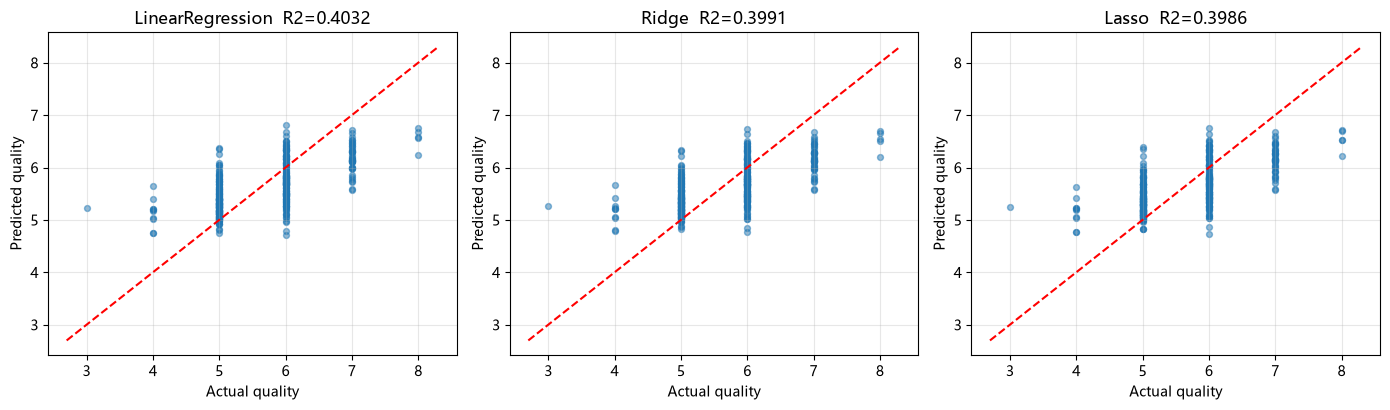

In [19]:
#画出真实值与预测值对比，越贴近对角线说明预测越准
fig,axes = plt.subplots(1,3,figsize=(14,4.2))
for ax,(name,pred) in zip(axes,
        [('LinearRegression',lr_predict),('Ridge',ridge_predict),('Lasso',lasso_predict)]):
    ax.scatter(y_test,pred,alpha=0.5,s=18)
    lim = [y_test.min()-0.3,y_test.max()+0.3]
    ax.plot(lim,lim,'r--',lw=1.5)
    ax.set_xlabel('Actual quality')
    ax.set_ylabel('Predicted quality')
    ax.set_title(name+'  R2='+str(round(r2_score(y_test,pred),4)))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

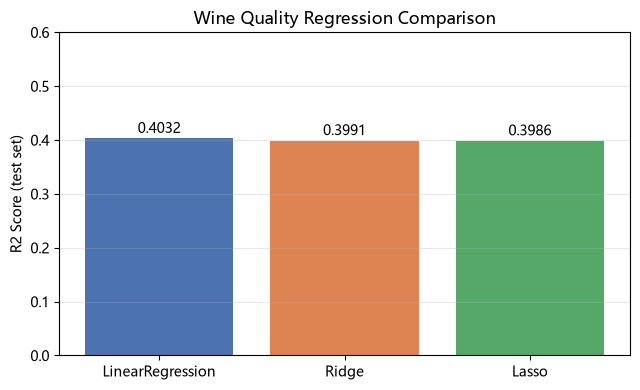

In [20]:
#三种模型 R2 对比
models = ['LinearRegression','Ridge','Lasso']
scores = [lr.score(X_test,y_test),ridge.score(X_test,y_test),lasso.score(X_test,y_test)]

plt.figure(figsize=(6.5,4))
bars = plt.bar(models,scores,color=['#4C72B0','#DD8452','#55A868'])
plt.ylim(0,0.6)
plt.ylabel('R2 Score (test set)')
plt.title('Wine Quality Regression Comparison')
for b,s in zip(bars,scores):
    plt.text(b.get_x()+b.get_width()/2,s+0.01,format(s,'.4f'),ha='center')
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()

## 七、模型评估汇总

In [21]:
#汇总各模型测试集指标
summary = pd.DataFrame({
    name: {'MSE':round(mean_squared_error(y_test,pred),1),
           'RMSE':round(mean_squared_error(y_test,pred)**0.5,2),
           'MAE':round(mean_absolute_error(y_test,pred),2),
           'R2':round(score,4)}
    for (name,pred),score in zip(
        [('LinearRegression',lr_predict),('Ridge',ridge_predict),('Lasso',lasso_predict)],scores)
}).T
summary

,MSE,RMSE,MAE,R2
LinearRegression,0.4,0.62,0.50,0.4032
Ridge,0.4,0.63,0.51,0.3991
Lasso,0.4,0.63,0.51,0.3986


## 八、实验总结

1. **流程复用**：本实验将 0909 中内置数据集的建模流程迁移到外部 CSV 数据集，`fit / predict / score` 接口用法完全一致，只是数据加载改为 pandas 读取并自行分离 `X / y`。
2. **三种回归对比**：LinearRegression、Ridge、Lasso 在测试集上的 R² 都在 0.40 左右，差距很小——因为该数据集特征间共线性不强、样本量适中，正则化收益有限，但 Ridge/Lasso 的系数更稳定。
3. **Lasso 的特征选择**：`LassoCV` 自动选出的 `alpha` 将部分弱相关特征压缩为 0，保留的特征中 `alcohol`（正向）、`volatile acidity`（负向）系数最大，与葡萄酒品鉴领域的常识一致：酒精度越高、挥发酸越低，质量评分通常越高。
4. **R² 偏低的原因**：`quality` 是 3~8 的离散人工评分，本质更偏向分类/排序问题，线性模型只能拟合其中的连续趋势，因此 R² 上限有限；这也是教材中常用该数据集合同时演示回归与分类的原因。
5. **评估指标**：`score()` 直接给出 R²，直观反映拟合优度；RMSE 对大误差敏感，MAE 更稳健，实际报告中应结合使用。